<a href="https://colab.research.google.com/github/SupriyoGain/Introduction-to-NLP-M26AIR014/blob/main/flowers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
# each point is length, width, type (0, 1)

data = [
    "I am Supriyo",
    "My friend is Prasun",
    "I love playing guitar",
    "Today is the first day of Deeksha mam's class",
    "Today is 10th October, 2026",
    "Prasun is typing so loudly"
]

label = [0, 1, 0, 1, 0, 0]

# Split each sentence into individual words
tokens = [sentence.split() for sentence in data]

print(tokens)

# Create a vocabulary containing unique words
vocabulary = list(dict.fromkeys(
    word for sentence in data for word in sentence.split()
))

print("Vocabulary:", vocabulary)
print("Vocabulary size:", len(vocabulary))

# Step 2: Create a one-hot vector for every word
word_to_one_hot = {}

for i, word in enumerate(vocabulary):
    vector = [0] * len(vocabulary)
    vector[i] = 1
    word_to_one_hot[word] = vector

# Step 3: Display the one-hot representation of every word
for word, vector in word_to_one_hot.items():
    print(word, ":", vector)

# Step 4: Convert each sentence into a sequence of one-hot vectors
sentence_vectors = [
    [word_to_one_hot[word] for word in sentence.split()]
    for sentence in data
]

print("\nOne-hot representation of the 1st sentence:")
print(sentence_vectors[0])
print("\nOne-hot representation of the 2nd sentence:")
print(sentence_vectors[1])
print("\nOne-hot representation of the 3rd sentence:")
print(sentence_vectors[2])
print("\nOne-hot representation of the 4th sentence:")
print(sentence_vectors[3])
print("\nOne-hot representation of the 5th sentence:")
print(sentence_vectors[4])
print("\nOne-hot representation of the 6th sentence:")
print(sentence_vectors[5])

mystery_flower = [5, 6]

[['I', 'am', 'Supriyo'], ['My', 'friend', 'is', 'Prasun'], ['I', 'love', 'playing', 'guitar'], ['Today', 'is', 'the', 'first', 'day', 'of', 'Deeksha', "mam's", 'class'], ['Today', 'is', '10th', 'October,', '2026'], ['Prasun', 'is', 'typing', 'so', 'loudly']]
Vocabulary: ['I', 'am', 'Supriyo', 'My', 'friend', 'is', 'Prasun', 'love', 'playing', 'guitar', 'Today', 'the', 'first', 'day', 'of', 'Deeksha', "mam's", 'class', '10th', 'October,', '2026', 'typing', 'so', 'loudly']
Vocabulary size: 24
I : [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
am : [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Supriyo : [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
My : [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
friend : [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
is : [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Prasun : [0, 0, 0, 0, 0, 0, 

In [ ]:
import numpy as np

# Create the 6 × 24 input matrix
X = np.zeros((len(data), len(vocabulary)))

word_to_index = {word: i for i, word in enumerate(vocabulary)}

for i, sentence in enumerate(data):
    for word in sentence.split():
        X[i, word_to_index[word]] += 1

print("Input matrix X:\n", X)
print("Shape of X:", X.shape)

# Initialize the weight matrix E (24 × 3)
np.random.seed(42)
E = np.random.randn(len(vocabulary), 3)

# Initialize bias (1 × 3)
b = np.zeros((1, 3))

# Calculate output: H = XE + b
H = X @ E + b

print("\nWeight matrix E:\n", E)
print("Shape of E:", E.shape)

print("\nBias b:\n", b)

print("\nFinal output H:\n", H)
print("Shape of H:", H.shape)

Input matrix X:
 [[1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]]
Shape of X: (6, 24)

Weight matrix E:
 [[ 0.49671415 -0.1382643   0.64768854]
 [ 1.52302986 -0.23415337 -0.23413696]
 [ 1.57921282  0.76743473 -0.46947439]
 [ 0.54256004 -0.46341769 -0.46572975]
 [ 0.24196227 -1.91328024 -1.72491783]
 [-0.56228753 -1.01283112  0.31424733]
 [-0.90802408 -1.4123037   1.46564877]
 [-0.2257763   0.0675282  -1.42474819]
 [-0.54438272  0.11092259 -1.15099358]
 [ 0.37569802 -0.60063869 -0.29169375]
 [-0.60170661  1.85227818 -0.01349722]
 [-1.05771093  0.82254491 -1.22084365]
 [ 0.2088636  -1.95967012

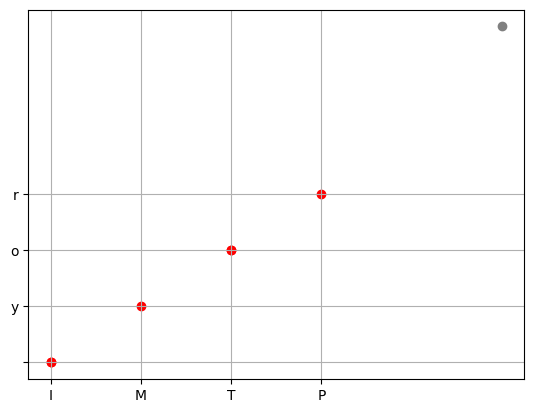

In [ ]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [ ]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [ ]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

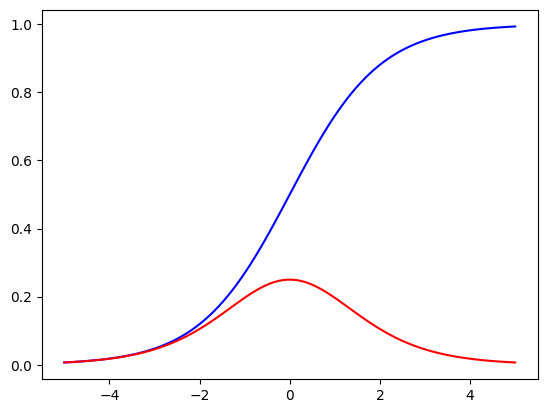

In [ ]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

In [ ]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 20000
    learning_rate = 1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = (pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += (p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

TypeError: can't multiply sequence by non-int of type 'float'

In [ ]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

In [ ]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()